# Georeferencing Exploration
Toponym recognition (spaCy `en_core_web_trf`) + GeoNames gazetteer applied to the normalized COVID corpus.

This notebook contains:
- Coverage of toponym extraction across phases and tiers
- Top countries/cities by tier
- Country-level temporal heatmaps
- Static per-phase KDE density maps
- A weekly geographic-attention GIF: separate low-credibility and authoritative maps, a shared percentage legend, and dated COVID milestones
- Hypothesis: does *low*-tier (false info) show wider geographic spread than *authoritative*?

Source tiers are resolved from the current credibility registry when the cached geography is loaded. Updating the curated domain list does not require rerunning NER.

In [1]:
import json
from collections import Counter
from datetime import date, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

palette = sns.color_palette("rocket", n_colors=7)
sns.set_style("whitegrid", {
    "axes.facecolor": "#ffffff",
    "figure.facecolor": "#ffffff",
    "grid.color": "#e0e0e0",
    "grid.linestyle": "--",
    "axes.spines.top": False,
    "axes.spines.right": False,
})
sns.set_palette(palette)
sns.set_context("notebook", font_scale=1.3, rc={
    "lines.linewidth": 2,
    "axes.linewidth": 1.2,
})
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

TIER_COLORS = {
    "low":           "#e91e63",  # magenta
    "authoritative": "#00bcd4",  # cyan
    "mixed":         "#ffc107",  # amber
}
TIER_ORDER = ["low", "authoritative", "mixed"]

In [ ]:
from config import (
    PROJECT_ROOT, PROCESSED_DIR, COVID_COLLECTIONS, PHASES_BY_NAME,
    PANDEMIC_PHASES, COVID_TIMELINE_EVENTS,
)

GEOREF_DIR = PROCESSED_DIR / "georef"
print(f"Georef dir: {GEOREF_DIR}")
print(f"Files found: {len(list(GEOREF_DIR.glob('*/documents.jsonl')))}")

In [ ]:
def load_georef(georef_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Load cached geography, resolving source tiers against the current registry."""
    rows = []
    for jsonl_path in sorted(georef_dir.glob("*/documents.jsonl")):
        with jsonl_path.open("r", encoding="utf-8") as fh:
            for line in fh:
                line = line.strip()
                if not line:
                    continue
                rows.append(json.loads(line))
    df = pd.DataFrame(rows)
    if df.empty:
        return df, df
    # Classification can evolve independently of expensive NER/gazetteer work.
    # Re-resolve before exploding mentions so document and mention tiers agree.
    from credibility import AUTHORITATIVE_DOMAINS, CredibilityRegistry
    registry = CredibilityRegistry.load(PROCESSED_DIR / "credibility.json").with_authoritative(AUTHORITATIVE_DOMAINS)
    cached_tiers = df["credibility_tier"].copy()
    df["credibility_tier"] = df["seed_url"].map(registry.lookup)
    changed = int(df["credibility_tier"].ne(cached_tiers).sum())
    print(f"Refreshed {changed:,} cached source-tier labels (geography unchanged)")
    from document_time import assign_document_time
    refreshed = [assign_document_time(row) for row in df.to_dict("records")]
    for field in ["phase", "capture_phase", "event_date", "event_date_source"]:
        df[field] = [row[field] for row in refreshed]
    df["event_date_source"] = df.event_date_source.map({"publish_date": "publish", "capture_timestamp": "capture"})
    df["event_dt"] = pd.to_datetime(df["event_date"], errors="coerce", utc=True).dt.tz_convert(None)
    df["event_week"] = df.event_dt.dt.strftime("%G-W%V")
    # Per-mention frame for spatial aggregations.
    mentions_rows = []
    for _, row in df.iterrows():
        for m in row["mentions"] or []:
            mentions_rows.append({
                "article_id": row["article_id"],
                "phase": row["phase"],
                "tier": row["credibility_tier"],
                "event_date": row["event_date"],
                "event_dt": row["event_dt"],
                "event_week": row["event_week"],
                "event_date_source": row["event_date_source"],
                "toponym": m["toponym"],
                "name": m["name"],
                "lat": m["lat"],
                "lon": m["lon"],
                "country_code": m["country_code"],
                "feature_class": m["feature_class"],
                "mention_count": m["mention_count"],
                "confidence": m["confidence"],
            })
    df_mentions = pd.DataFrame(mentions_rows)
    return df, df_mentions

df_docs, df_mentions = load_georef(GEOREF_DIR)
print(f"Docs: {len(df_docs):,}")
print(f"Mentions (exploded): {len(df_mentions):,}")
if df_docs.empty:
    raise SystemExit("No georef data. Run `uv run python scripts/georef.py <cid> all` first.")
df_docs.head(3)

## 1. Coverage diagnostics

NER status distribution:
  ok: 6,478 (71.8%)
  no_toponyms: 2,548 (28.2%)

Overall toponym coverage: 71.8%  (target >= 70%)


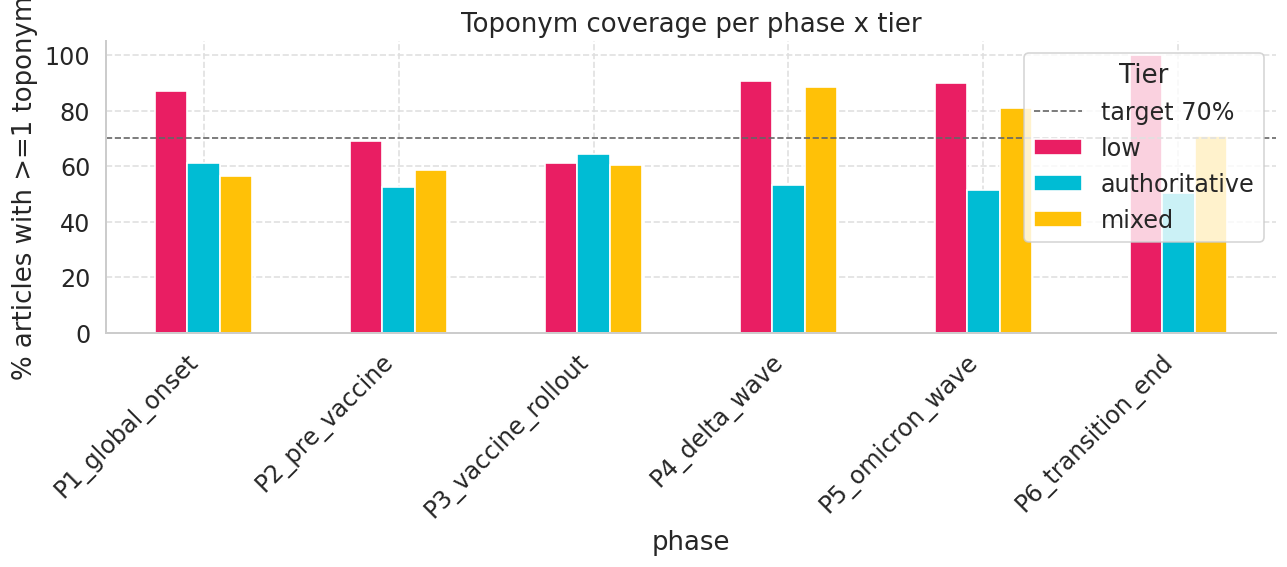

In [4]:
ner_status_counts = df_docs["ner_status"].value_counts()
print("NER status distribution:")
for status, count in ner_status_counts.items():
    print(f"  {status}: {count:,} ({100 * count / len(df_docs):.1f}%)")

ok_rate = (df_docs["ner_status"] == "ok").mean()
print(f"\nOverall toponym coverage: {ok_rate * 100:.1f}%  (target >= 70%)")

# Coverage per tier x phase
df_docs["is_ok"] = (df_docs["ner_status"] == "ok").astype(int)
coverage = (
    df_docs.groupby(["phase", "credibility_tier"])["is_ok"]
    .agg(["sum", "count"]).reset_index()
)
coverage["rate"] = 100 * coverage["sum"] / coverage["count"].clip(lower=1)
pivot = coverage.pivot(index="phase", columns="credibility_tier", values="rate").fillna(0)
phase_order = [p.name for p in PANDEMIC_PHASES if p.name in pivot.index]
pivot = pivot.loc[phase_order]

fig, ax = plt.subplots(figsize=(11, 5))
pivot[[t for t in TIER_ORDER if t in pivot.columns]].plot(
    kind="bar", ax=ax,
    color=[TIER_COLORS[t] for t in TIER_ORDER if t in pivot.columns],
    edgecolor="white",
)
ax.axhline(70, color="#666", linestyle="--", linewidth=1, label="target 70%")
ax.set_ylabel("% articles with >=1 toponym")
ax.set_title("Toponym coverage per phase x tier")
ax.legend(title="Tier")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

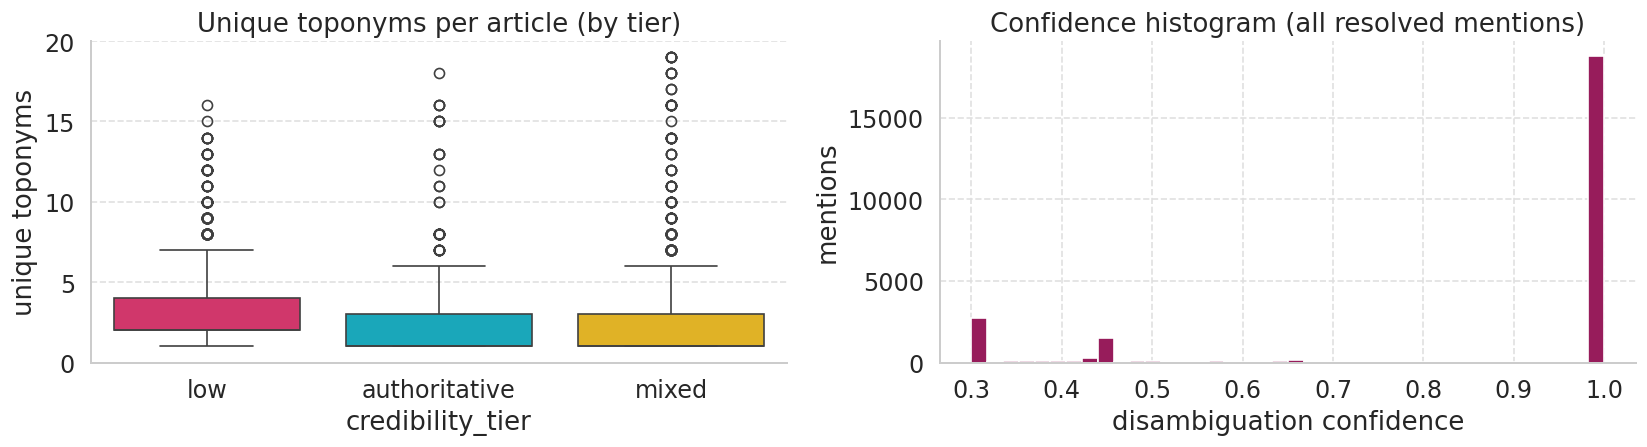


Dispersion + entropy summary by tier (ok docs only):
credibility_tier        authoritative          low        mixed
dispersion_km    count     935.000000  3613.000000  1930.000000
                 mean     1502.159872  2908.137272  1051.674382
                 std      2164.664652  2174.816105  1896.528191
                 min         0.000000     0.000000     0.000000
                 25%         0.000000   610.063182     0.000000
                 50%         0.000000  3211.171972     0.000000
                 75%      3056.270856  4510.767684  1209.442139
                 max      8623.670671  9492.929366  8425.455565
country_entropy  count     935.000000  3613.000000  1930.000000
                 mean        0.552242     1.122063     0.421819
                 std         0.832955     0.881263     0.917164
                 min         0.000000     0.000000     0.000000
                 25%         0.000000     0.000000     0.000000
                 50%         0.000000     1.000000

In [5]:
# Mention count distribution per article (tier-grouped) and confidence histogram
df_docs["n_mentions"] = df_docs["mentions"].apply(
    lambda ms: sum(m["mention_count"] for m in (ms or []))
)
df_docs["n_unique_topo"] = df_docs["mentions"].apply(lambda ms: len(ms or []))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ok_docs = df_docs[df_docs["ner_status"] == "ok"]
sns.boxplot(
    data=ok_docs, x="credibility_tier", y="n_unique_topo",
    order=[t for t in TIER_ORDER if t in ok_docs["credibility_tier"].unique()],
    palette=TIER_COLORS, ax=axes[0],
)
axes[0].set_ylim(0, max(20, ok_docs["n_unique_topo"].quantile(0.95)))
axes[0].set_title("Unique toponyms per article (by tier)")
axes[0].set_ylabel("unique toponyms")

axes[1].hist(
    df_mentions["confidence"], bins=40, color=palette[2],
    edgecolor="white",
)
axes[1].set_xlabel("disambiguation confidence")
axes[1].set_ylabel("mentions")
axes[1].set_title("Confidence histogram (all resolved mentions)")
plt.tight_layout()
plt.show()

print(f"\nDispersion + entropy summary by tier (ok docs only):")
print(
    ok_docs.groupby("credibility_tier")[["dispersion_km", "country_entropy", "unique_countries"]]
    .describe().T
)

In [6]:
# event_date_source audit: how often did we have to fall back from publish to capture?
src_per_tier = (
    df_docs.groupby(["credibility_tier", "event_date_source"]).size()
    .unstack(fill_value=0)
)
src_per_tier["publish_pct"] = 100 * src_per_tier.get("publish", 0) / src_per_tier.sum(axis=1)
print("event_date source by tier:")
print(src_per_tier)

publish_overall = 100 * (df_docs["event_date_source"] == "publish").mean()
print(f"\nOverall publish_date coverage: {publish_overall:.1f}%")
if publish_overall < 40:
    print("  WARNING: publish_date is sparse; weekly animation effectively reflects harvest schedule.")

event_date source by tier:
event_date_source  capture  publish  publish_pct
credibility_tier                                
authoritative            0     1685    100.00000
low                      0     4590    100.00000
mixed                   72     2679     97.38277

Overall publish_date coverage: 99.2%


## 2. Top countries and cities, by tier

In [7]:
for tier in TIER_ORDER:
    sub = df_mentions[df_mentions["tier"] == tier]
    if sub.empty:
        continue
    print(f"\n=== {tier}: top 10 countries (by weighted mentions) ===")
    top = (
        sub.groupby("country_code")["mention_count"].sum()
        .sort_values(ascending=False).head(10)
    )
    for cc, n in top.items():
        print(f"  {cc or '??'}: {int(n):,}")

    print(f"--- top 10 cities ---")
    top_city = (
        sub.groupby(["name", "country_code"])["mention_count"].sum()
        .sort_values(ascending=False).head(10)
    )
    for (city, cc), n in top_city.items():
        print(f"  {city} ({cc}): {int(n):,}")


=== low: top 10 countries (by weighted mentions) ===
  US: 4,217
  CN: 1,993
  FR: 1,648
  NL: 1,266
  RU: 1,000
  GE: 700
  AF: 559
  CU: 436
  UA: 385
  JP: 322
--- top 10 cities ---
  Beijing (CN): 1,807
  Us (FR): 1,533
  America (NL): 1,253
  Tbilisi (GE): 697
  Washington (US): 660
  Moscow (RU): 623
  California (US): 571
  Kabul (AF): 556
  New York City (US): 433
  Uk (RU): 364

=== authoritative: top 10 countries (by weighted mentions) ===
  CN: 4,086
  US: 1,946
  TW: 878
  IN: 817
  HK: 382
  CA: 347
  FR: 306
  RU: 255
  AU: 166
  IT: 138
--- top 10 cities ---
  Beijing (CN): 3,361
  Taipei (TW): 878
  New Delhi (IN): 762
  Wuhan (CN): 640
  Washington (US): 450
  Hong Kong (HK): 378
  Ottawa (CA): 319
  Us (FR): 266
  Uk (RU): 255
  Bismarck (US): 193

=== mixed: top 10 countries (by weighted mentions) ===
  US: 11,952
  MY: 4,280
  CN: 1,813
  AU: 1,002
  FR: 742
  CA: 678
  RU: 596
  GB: 524
  BR: 511
  JP: 498
--- top 10 cities ---
  Kuala Lumpur (MY): 4,118
  Washing

In [ ]:
from normalize import load_normalized

NORMALIZED_DIR = PROCESSED_DIR / "normalized"

def find_article_by_id(article_id: str):
    cid, sid, ts = article_id.split(":", 2)
    for path in (NORMALIZED_DIR / cid).glob("documents.jsonl"):
        for doc in load_normalized(path):
            if (str(doc.collection_id) == cid and str(doc.seed_id) == sid
                    and doc.capture_timestamp == ts):
                return doc
    return None

for query in ["Wuhan", "Bergamo", "New York"]:
    print(f"\n{'=' * 78}\nQuery: title contains '{query}'")
    cand = df_docs[
        df_docs.apply(lambda r: bool(r.get("mentions")) and any(
            query.lower() in (m["name"] or "").lower() for m in r["mentions"]
        ), axis=1)
    ].head(2)
    if cand.empty:
        print("  no articles mention this place")
        continue
    for _, row in cand.iterrows():
        print(f"\n--- {row['article_id']} ({row['credibility_tier']}, {row['phase']}) ---")
        print(f"  seed: {row['seed_url']}")
        print(f"  mentions ({len(row['mentions'])}):")
        for m in sorted(row["mentions"], key=lambda x: -x["mention_count"])[:8]:
            print(
                f"    - {m['name']:<24} ({m['country_code']})"
                f"  count={m['mention_count']:<3} conf={m['confidence']:.2f}"
            )
#TODO: investigate Middle East (US), Us (FR), Uk (RU) 

## 3. Country-level temporal heatmap

Rows = top 30 mentioned countries, columns = phases. Cell = log10(mention_count)

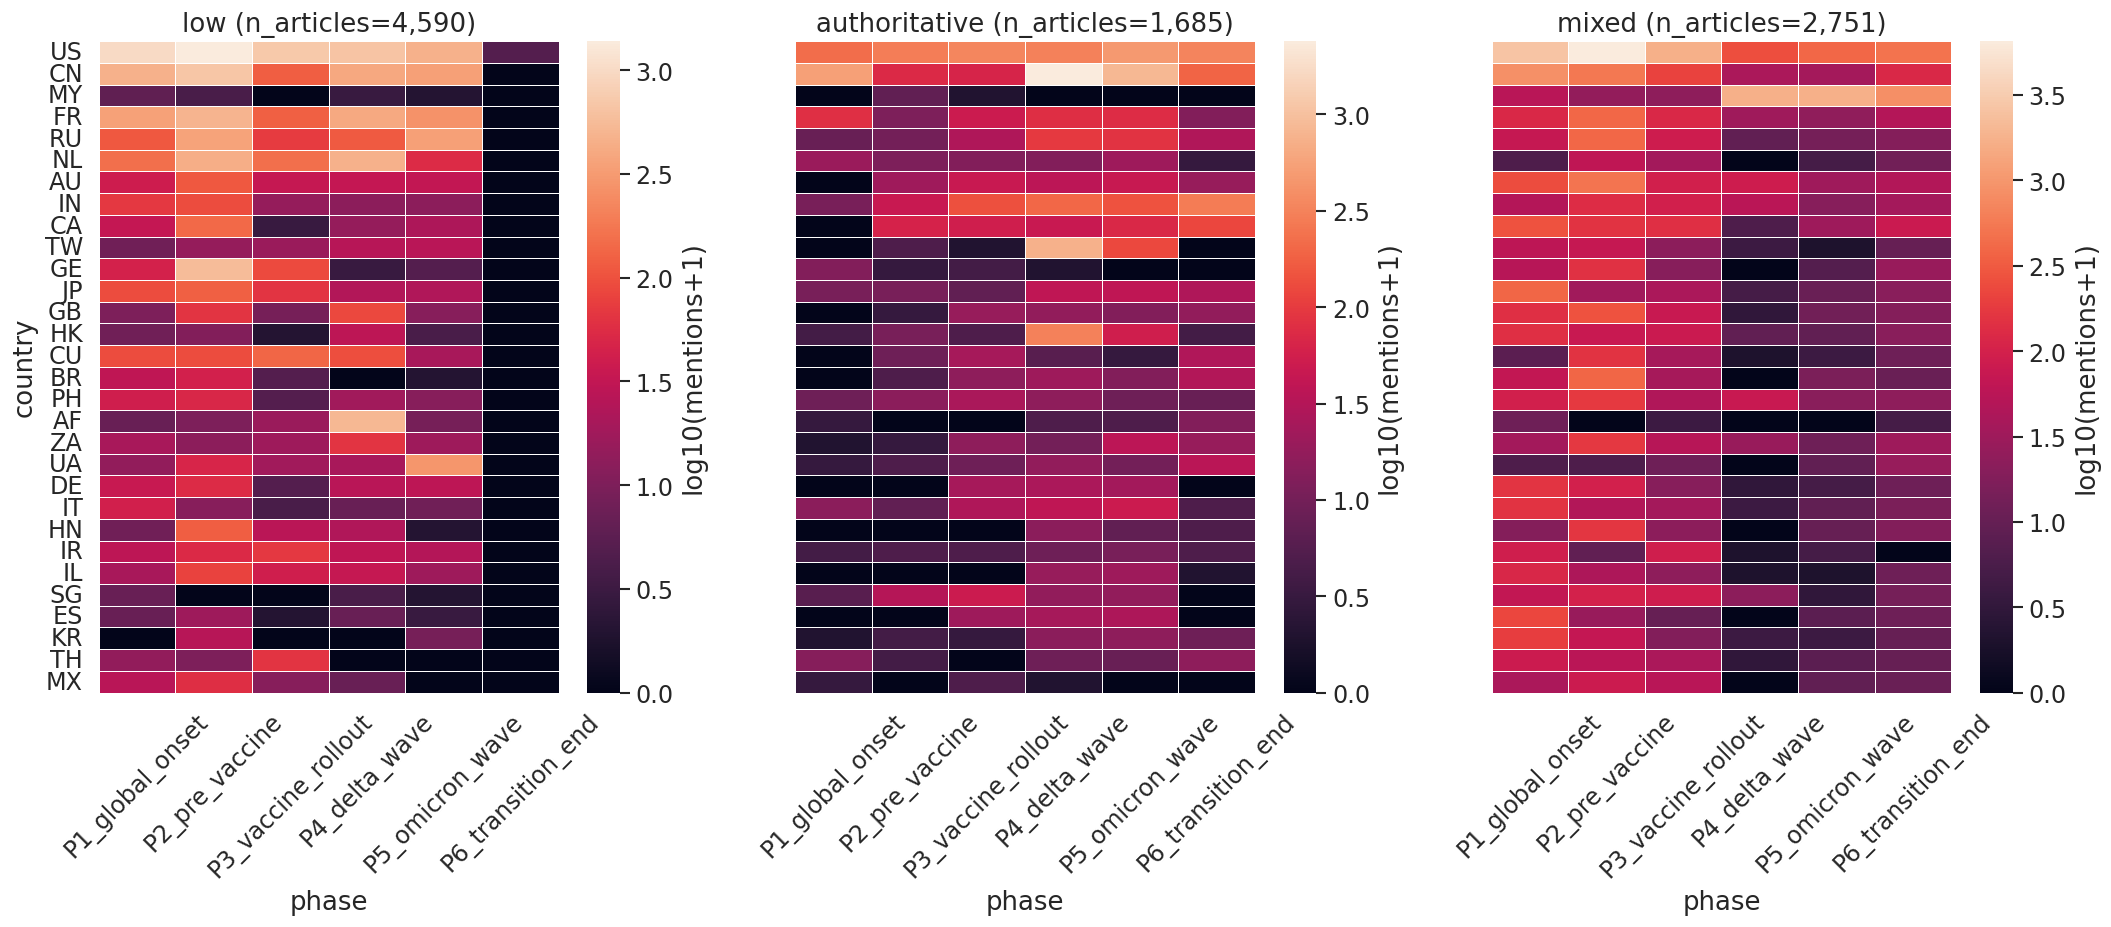

In [9]:
phase_order_present = [p.name for p in PANDEMIC_PHASES if p.name in df_mentions["phase"].unique()]
top_countries = (
    df_mentions.groupby("country_code")["mention_count"].sum()
    .sort_values(ascending=False).head(30).index.tolist()
)

tiers_with_data = [t for t in TIER_ORDER if t in df_mentions["tier"].unique()]
fig, axes = plt.subplots(1, len(tiers_with_data), figsize=(6 * len(tiers_with_data), 8), sharey=True)
if len(tiers_with_data) == 1:
    axes = [axes]

for ax, tier in zip(axes, tiers_with_data):
    sub = df_mentions[df_mentions["tier"] == tier]
    pivot = (
        sub.groupby(["country_code", "phase"])["mention_count"].sum()
        .unstack(fill_value=0).reindex(top_countries)
        .reindex(columns=phase_order_present, fill_value=0)
    )
    sns.heatmap(
        np.log10(pivot + 1), ax=ax, cmap="rocket",
        cbar_kws={"label": "log10(mentions+1)"},
        linewidths=0.4, linecolor="white",
    )
    ax.set_title(f"{tier} (n_articles={(df_docs['credibility_tier']==tier).sum():,})")
    ax.set_xlabel("phase")
    ax.set_ylabel("country" if ax is axes[0] else "")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 4. Static per-phase maps

Per (phase, tier): weighted Gaussian KDE on `(lon, lat)` mention points, evaluated on a 360x180 grid to test visualization 

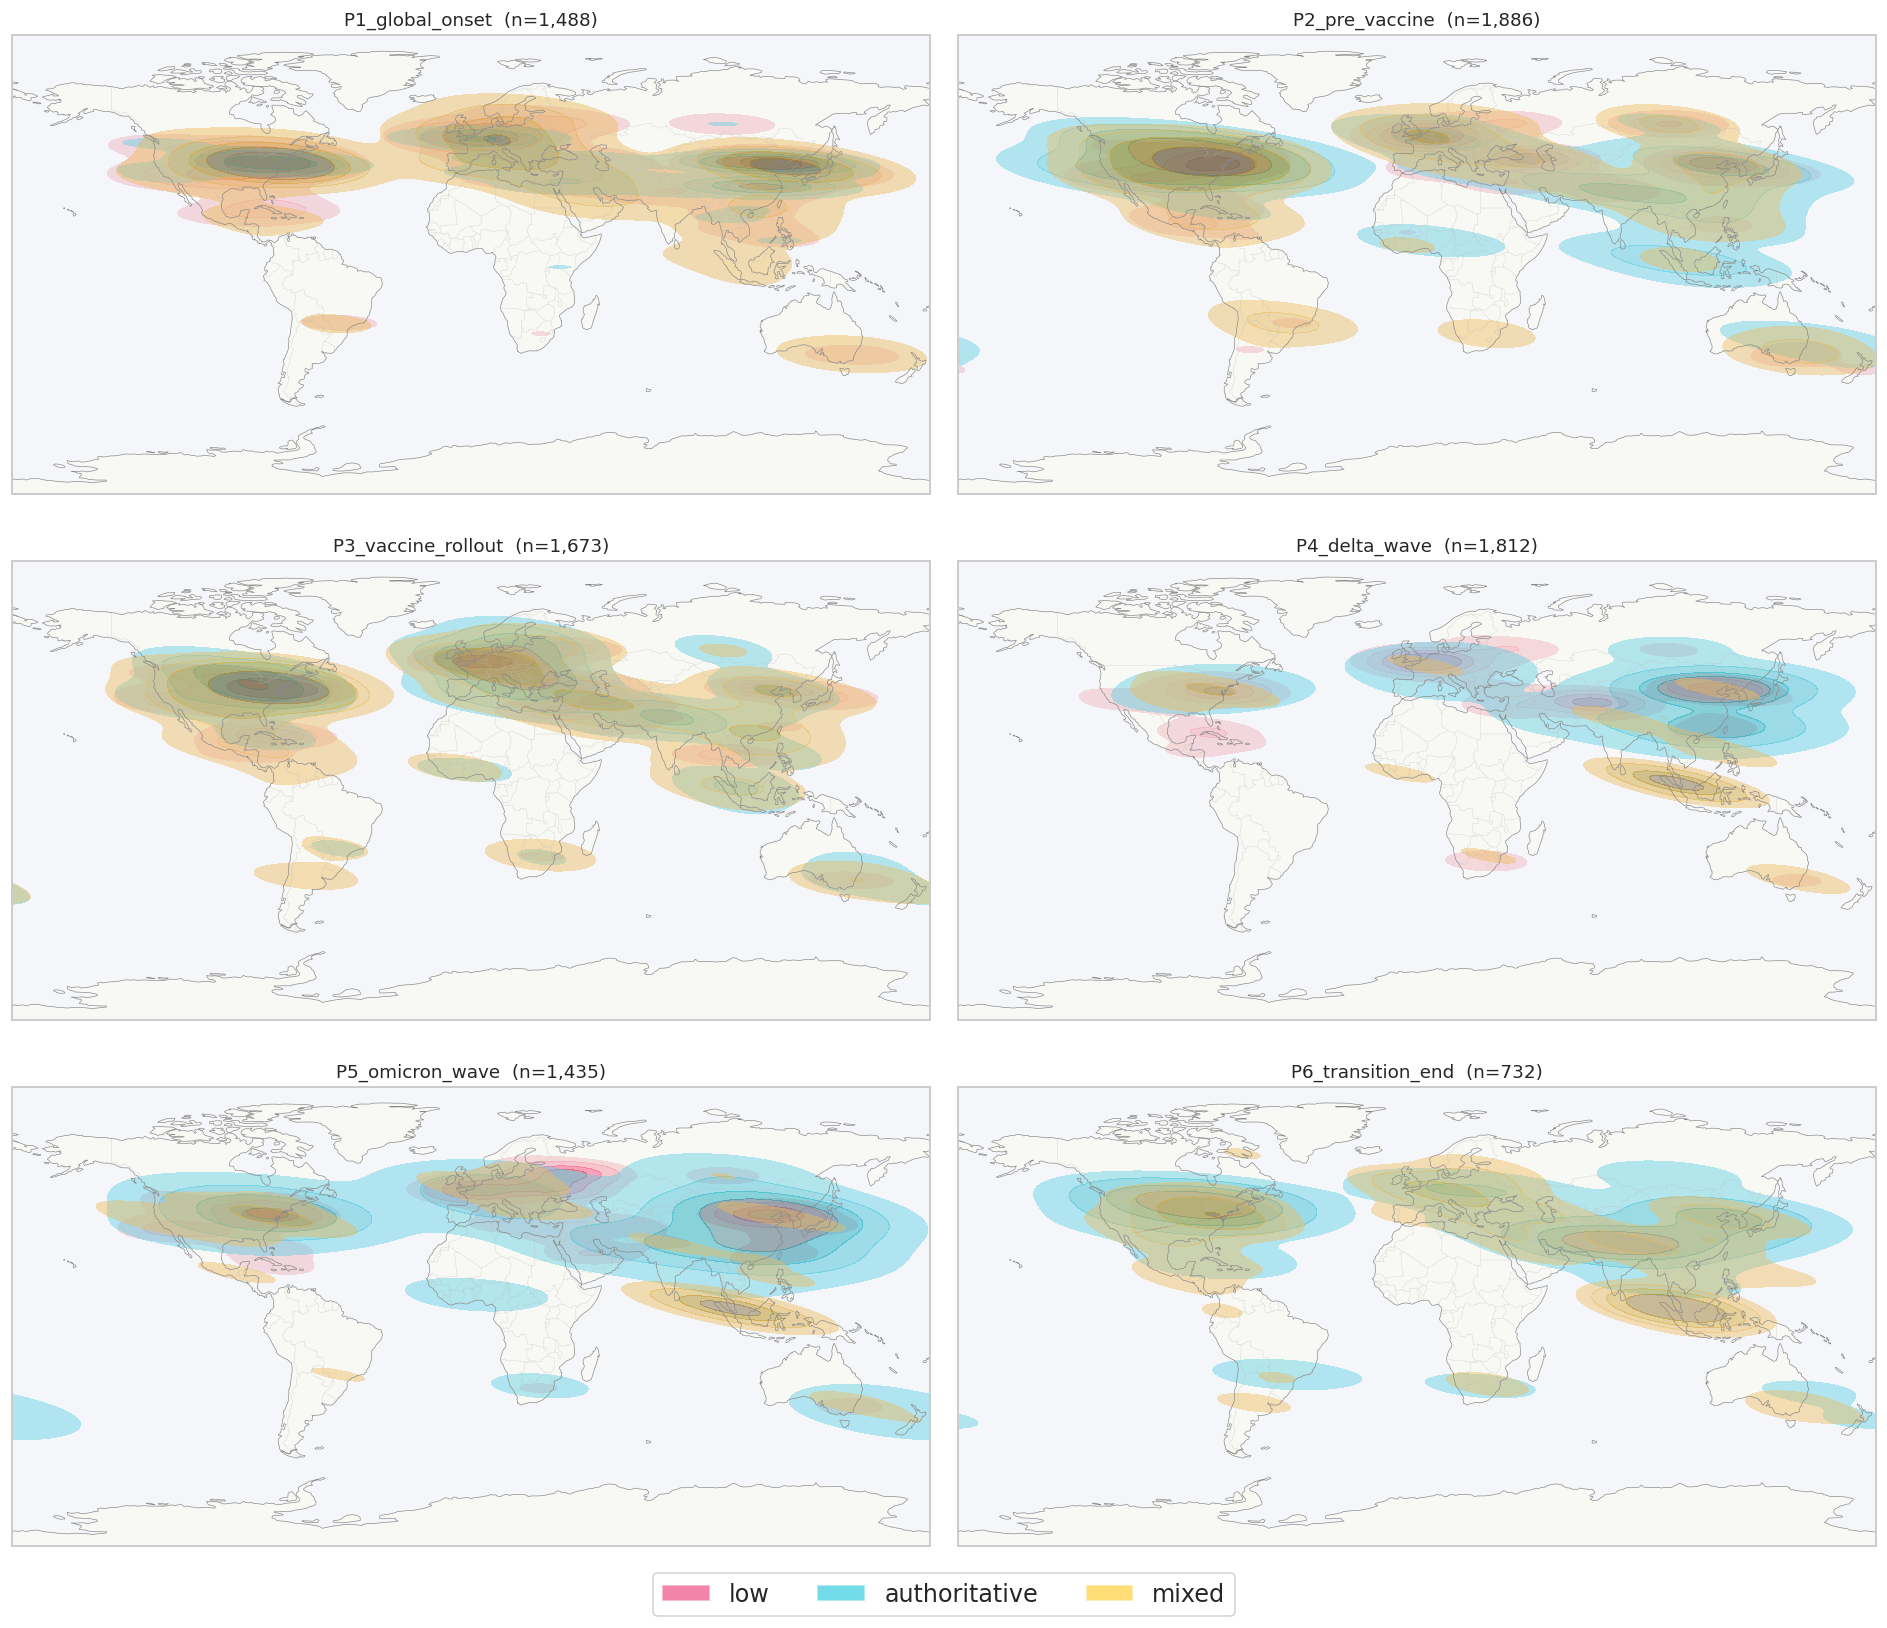

In [10]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import seaborn as sns

def draw_basemap(ax) -> None:
    ax.set_global()
    ax.add_feature(cfeature.OCEAN, facecolor="#f4f6fa")
    ax.add_feature(cfeature.LAND, facecolor="#f8f8f4", edgecolor="none")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.4, edgecolor="#888")
    ax.add_feature(cfeature.BORDERS, linewidth=0.25, edgecolor="#bbb", alpha=0.6)

def draw_kde(ax, points_by_tier: dict[str, pd.DataFrame]) -> None:
    for tier in TIER_ORDER:
        pts = points_by_tier.get(tier)
        if pts is None or pts.empty or len(pts) < 3:
            continue
        sns.kdeplot(
            x=pts["lon"].values,
            y=pts["lat"].values,
            weights=pts["mention_count"].values.astype(float),
            ax=ax,
            fill=True,
            color=TIER_COLORS[tier],
            alpha=0.45,
            bw_adjust=0.5,
            thresh=0.1,       # fraction of peak density to cut off at (like ISO_THRESHOLD)
            levels=5,
        )

# --- Plot ---
phases_to_plot = phase_order_present
n_panels = len(phases_to_plot)
n_cols = 2
n_rows = (n_panels + n_cols - 1) // n_cols

fig = plt.figure(figsize=(16, 4.5 * n_rows))

for i, phase_name in enumerate(phases_to_plot):
    ax = fig.add_subplot(n_rows, n_cols, i + 1, projection=ccrs.PlateCarree())
    draw_basemap(ax)

    pts_by_tier = {
        t: df_mentions[(df_mentions["phase"] == phase_name) & (df_mentions["tier"] == t)]
        for t in TIER_ORDER
    }
    draw_kde(ax, pts_by_tier)

    n_articles = (df_docs["phase"] == phase_name).sum()
    ax.set_title(f"{phase_name}  (n={n_articles:,})", fontsize=11)

# Legend
from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=TIER_COLORS[t], alpha=0.55, label=t) for t in TIER_ORDER]
fig.legend(handles=legend_handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
plt.show()

## 5. Geographic attention of misinformation vs authoritative sources

Two **Robinson-projection country maps** compare misinformation and authoritative articles. Each map uses its tier's colour; the compact **grayscale legend** shows the shared intensity scale. The mixed tier is excluded. Each frame ends on Sunday (the last frame ends on 5 May 2023) and covers the preceding **4 calendar weeks**.

Country shading = percentage of that tier's **mapped articles** mentioning the country. An article counts once per country; an article may mention several countries. The percentage scale stays fixed across tiers and time. Unshaded countries have no mentions. Panels with fewer than **3 mapped articles** show a coverage message, and each panel reports mapped / total articles. Small territories absent from Natural Earth's 110m map are excluded from the mapped denominator.

**Events appear beneath the timeline as they occur**, with brief reading pauses; the latest event stays visible between milestones. Only past events receive timeline markers. The maps occupy the full width, without a milestone sidebar, country rankings, phase labels or provenance footer. Event descriptions and Wikipedia sources are in the catalogue below.

These are **places mentioned by archived articles**, not case counts, article origins, or the geographic spread of infections. Milestones provide context, not evidence of causality. Publication dates are used when available, with capture-date fallback (see the date-source audit above). Dispersion and entropy remain in the separate hypothesis analysis below.


In [11]:
from analysis.georeferencing_animation import create_georeferencing_animation, trailing_window

WINDOW_WEEKS = 4
MIN_ARTICLES_PER_TIER = 3

# Keep the hypothesis analysis within the configured sampling phases.
# The animation independently includes the earlier outbreak milestones.
min_dt = pd.Timestamp(PANDEMIC_PHASES[0].start)
max_dt = pd.Timestamp(PANDEMIC_PHASES[-1].end)
df_docs_dt = df_docs.loc[
    df_docs["event_dt"].ge(min_dt)
    & df_docs["event_dt"].lt(max_dt + pd.Timedelta(days=1))
].copy()
weeks = pd.date_range(min_dt - pd.Timedelta(days=min_dt.weekday()), max_dt, freq="W-MON")

def window_slice(frame, week):
    return trailing_window(frame, min(pd.Timestamp(week) + pd.Timedelta(days=6), max_dt), WINDOW_WEEKS)

print(f"Analysis date window: {min_dt.date()} to {max_dt.date()}; {len(df_docs_dt):,} articles")

Analysis date window: 2020-01-31 to 2023-05-05; 7,364 articles


In [12]:
story = create_georeferencing_animation(
    df_docs, df_mentions,
    events=COVID_TIMELINE_EVENTS,
    phases=PANDEMIC_PHASES,
    window_weeks=WINDOW_WEEKS,
    min_articles=MIN_ARTICLES_PER_TIER,
    interval=350,
)
anim = story.animation
print(f"Animation: {len(story.frame_ends)} frames; {len(COVID_TIMELINE_EVENTS)} historical milestones")
plt.close(story.figure)

Animation: 175 frames; 14 historical milestones


Writing /home/ala-adn/code/credleaf/notebooks/animation_out/weekly_KDE.gif ...


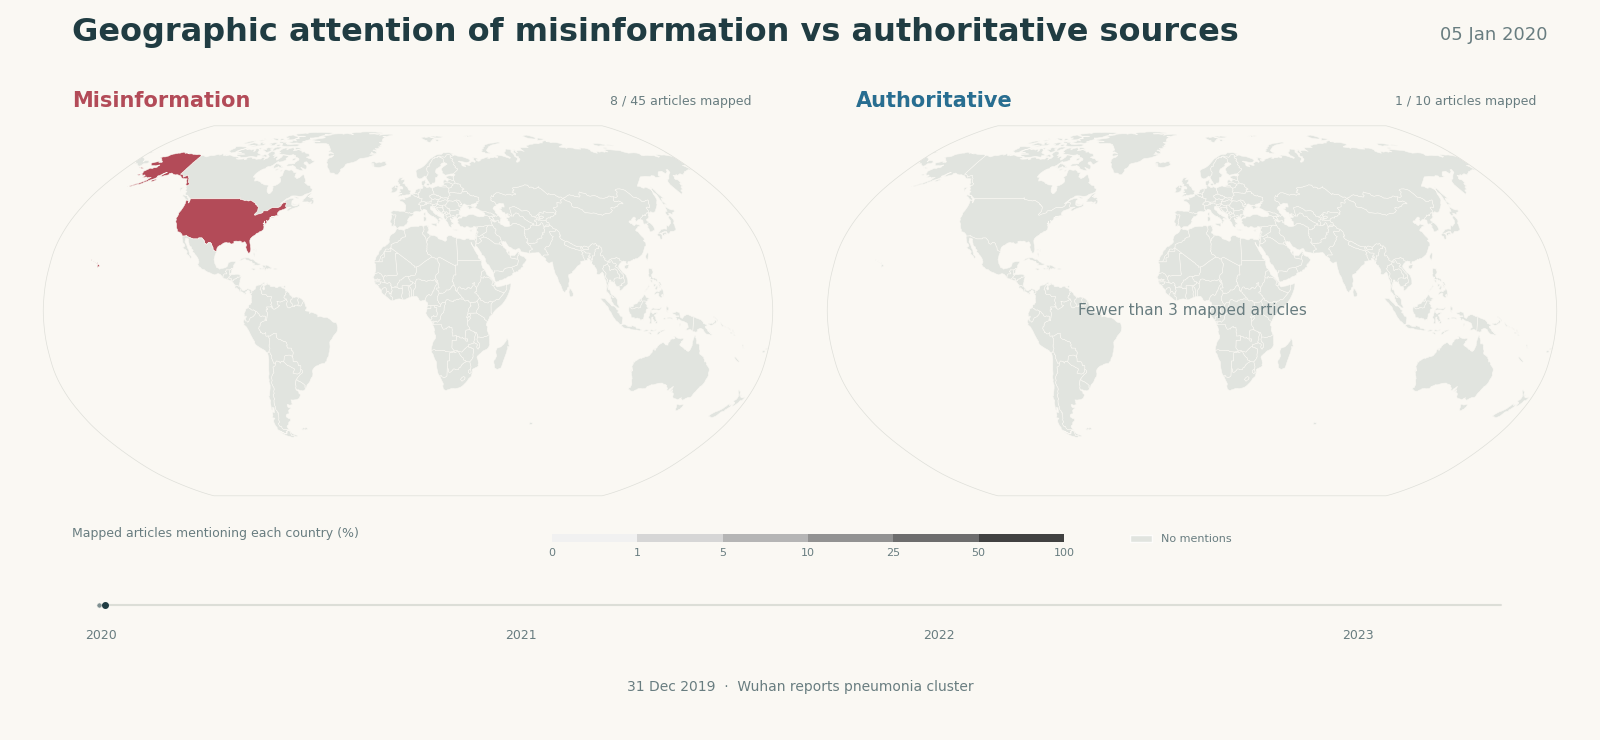

Saved 5.0 MiB


In [13]:
# Export the same animation shown below, then embed the GIF instead of hundreds
# of base64 PNGs in to_jshtml(). Paths work from either the repo or notebooks/.
from IPython.display import Image, display
from matplotlib.animation import PillowWriter

out_dir = PROJECT_ROOT / "notebooks" / "animation_out"
out_dir.mkdir(parents=True, exist_ok=True)
# Retain the established filename so existing links keep working.
gif_path = out_dir / "weekly_KDE.gif"
print(f"Writing {gif_path} ...")
anim.save(gif_path, writer=PillowWriter(fps=1000 / anim.event_source.interval), dpi=100,
          savefig_kwargs={"facecolor": story.figure.get_facecolor()})
display(Image(filename=str(gif_path)))
print(f"Saved {gif_path.stat().st_size / 1024**2:.1f} MiB")

**Interpretation:** compare countries with the same colour scale, then check each panel's sample size before interpreting changes. Blank or sparse windows indicate missing archive coverage. Historical events provide context; the animation does not establish causality.

In [14]:
# Auditable event catalogue. Full descriptions and Wikipedia links live in config.py.
pd.DataFrame([
    {"date": event.date, "event": event.title,
     "context": event.description, "Wikipedia source": event.source_url}
    for event in COVID_TIMELINE_EVENTS
])

,date,event,context,Wikipedia source
0,2019-12-31,Wuhan reports pneumonia cluster,Wuhan health officials publish a notice about ...,https://en.wikipedia.org/wiki/Timeline_of_the_...
1,2020-01-23,Wuhan enters lockdown,Travel restrictions begin in Wuhan as the outb...,https://en.wikipedia.org/wiki/Timeline_of_the_...
2,2020-01-30,WHO declares global emergency,WHO declares a Public Health Emergency of Inte...,https://en.wikipedia.org/wiki/Timeline_of_the_...
3,2020-03-09,Italy announces national lockdown,Italy extends movement restrictions across the...,https://en.wikipedia.org/wiki/COVID-19_lockdow...
4,2020-03-11,WHO characterizes a pandemic,WHO describes the worldwide COVID-19 outbreak ...,https://en.wikipedia.org/wiki/Timeline_of_the_...
5,2020-03-24,India announces national lockdown,"A 21-day nationwide lockdown is announced, sta...",https://en.wikipedia.org/wiki/Responses_to_the...
6,2020-04-02,One million confirmed cases,Reported COVID-19 cases worldwide pass one mil...,https://en.wikipedia.org/wiki/Timeline_of_the_...
7,2020-12-02,UK authorizes Pfizer vaccine,The UK authorizes the Pfizer-BioNTech vaccine ...,https://en.wikipedia.org/wiki/Responses_to_the...
8,2020-12-08,UK begins Pfizer vaccinations,The UK begins its public Pfizer-BioNTech vacci...,https://en.wikipedia.org/wiki/Responses_to_the...
9,2021-05-31,WHO introduces the Delta name,"WHO assigns Greek-letter names to variants, in...",https://en.wikipedia.org/wiki/SARS-CoV-2_Delta...


## 6. Hypothesis tests 

hypothesis: *false info shows aggressive geographic spread; true info stays coherent and steady.*
thus we define:
- `dispersion_km` (mean great-circle distance from per-article centroid)
- `country_entropy` (Shannon entropy over country distribution)

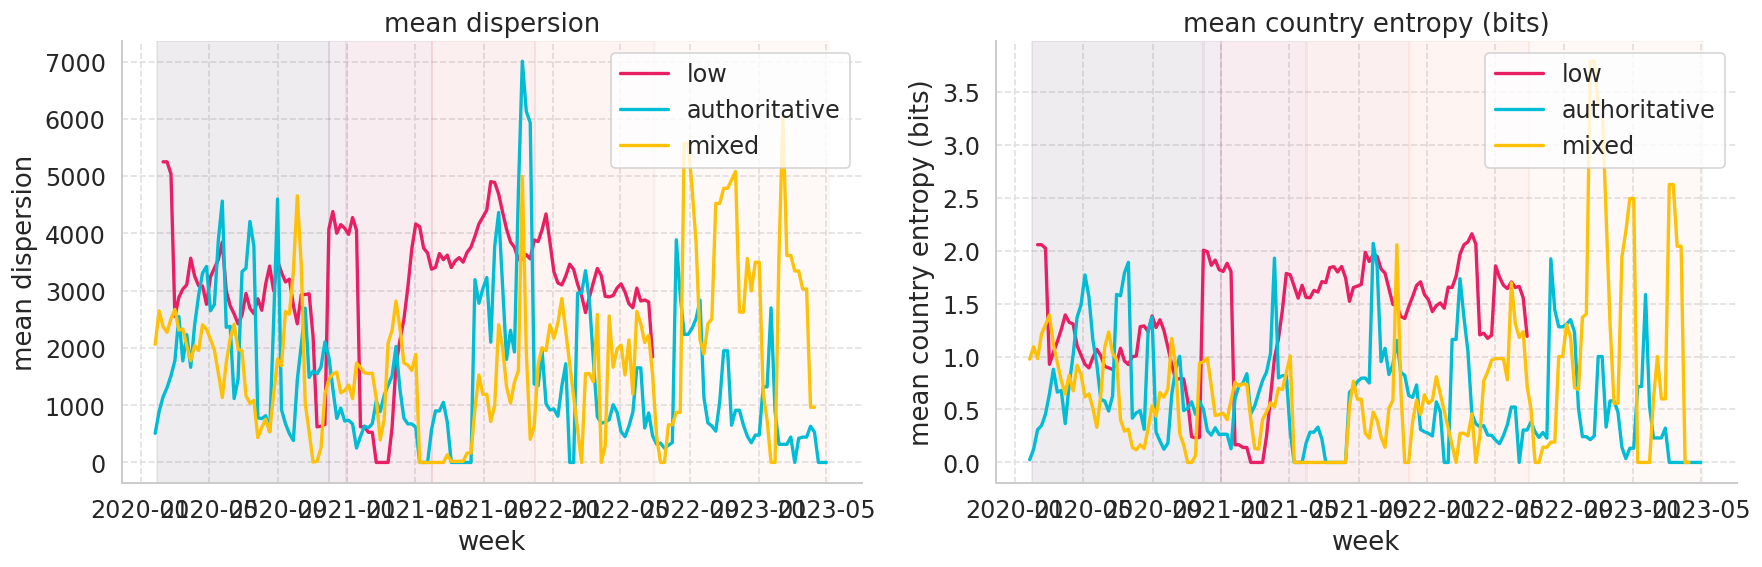


Phase-aggregated means:
                                     dispersion_km  country_entropy
phase              credibility_tier                                
P1_global_onset    authoritative           2580.77             0.84
                   low                     2684.50             0.92
                   mixed                   2495.41             1.46
P2_pre_vaccine     authoritative           1030.50             0.39
                   low                     3551.34             1.55
                   mixed                   1642.33             0.57
P3_vaccine_rollout authoritative            949.26             0.61
                   low                     3107.73             0.96
                   mixed                   1889.16             0.78
P4_delta_wave      authoritative           2245.59             0.62
                   low                     2580.11             0.98
                   mixed                    341.54             0.09
P5_omicron_wave    auth

In [15]:
phase_band_colors = sns.color_palette("rocket", n_colors=len(PANDEMIC_PHASES))

# Build a (week, tier) rolling table for both metrics.
metrics = []
for w in weeks:
    docs_w = window_slice(df_docs_dt, w)
    docs_ok = docs_w[docs_w["ner_status"] == "ok"]
    for tier in TIER_ORDER:
        sub = docs_ok[docs_ok["credibility_tier"] == tier]
        metrics.append({
            "week": pd.Timestamp(w),
            "tier": tier,
            "dispersion_km": sub["dispersion_km"].mean() if not sub.empty else np.nan,
            "country_entropy": sub["country_entropy"].mean() if not sub.empty else np.nan,
            "n": len(sub),
        })
met_df = pd.DataFrame(metrics)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
for ax, col, label in [
    (axes[0], "dispersion_km", "mean dispersion"),
    (axes[1], "country_entropy", "mean country entropy (bits)"),
]:
    for tier in TIER_ORDER:
        sub = met_df[met_df["tier"] == tier].dropna(subset=[col])
        if sub.empty:
            continue
        ax.plot(sub["week"], sub[col], color=TIER_COLORS[tier], linewidth=2, label=tier)
    # Phase shading
    for color, p in zip(phase_band_colors, PANDEMIC_PHASES):
        ax.axvspan(pd.Timestamp(p.start), pd.Timestamp(p.end), color=color, alpha=0.08)
    ax.set_ylabel(label)
    ax.set_title(label)
    ax.legend(loc="upper right")
axes[0].set_xlabel("week")
axes[1].set_xlabel("week")
plt.tight_layout()
plt.show()

# Phase-aggregated comparison table
print("\nPhase-aggregated means:")
phase_table = (
    df_docs[df_docs["ner_status"] == "ok"]
    .groupby(["phase", "credibility_tier"])[["dispersion_km", "country_entropy"]]
    .mean().round(2)
)
print(phase_table)

In [16]:
from scipy import stats
df_test = ok_docs[ok_docs["credibility_tier"].isin(["low", "authoritative"])].copy()
def compare_groups(df, metric, group_col="credibility_tier", group_a="authoritative", group_b="low"):
    a = df[df[group_col] == group_a][metric].dropna()
    b = df[df[group_col] == group_b][metric].dropna()
    
    # t-test (unequal variance)
    t_stat, p_t = stats.ttest_ind(a, b, equal_var=False)
    # Mann-Whitney U test
    u_stat, p_mw = stats.mannwhitneyu(a, b, alternative='two-sided')
    
    return pd.Series({
        "authoritative_mean": a.mean(),
        "low_mean": b.mean(),
        "diff (low - authoritative)": b.mean() - a.mean(),
        "t_stat": t_stat,
        "p_value_t": p_t,
        "u_stat": u_stat,
        "p_value_mw": p_mw,
        "authoritative_n": len(a),
        "low_n": len(b)
    })

# Run for both metrics
res_disp = compare_groups(df_test, "dispersion_km")
res_entr = compare_groups(df_test, "country_entropy")

with pd.option_context('display.float_format', '{:.4e}'.format):
    print("=== Dispersion (km) ===")
    print(res_disp.to_string())
    print("\n=== Country Entropy (bits) ===")
    print(res_entr.to_string())

=== Dispersion (km) ===
authoritative_mean            1.5022e+03
low_mean                      2.9081e+03
diff (low - authoritative)    1.4060e+03
t_stat                       -1.7685e+01
p_value_t                     1.4467e-63
u_stat                        1.0578e+06
p_value_mw                    3.4762e-71
authoritative_n               9.3500e+02
low_n                         3.6130e+03

=== Country Entropy (bits) ===
authoritative_mean            5.5224e-01
low_mean                      1.1221e+00
diff (low - authoritative)    5.6982e-01
t_stat                       -1.8420e+01
p_value_t                     1.4972e-68
u_stat                        1.0361e+06
p_value_mw                    7.7535e-78
authoritative_n               9.3500e+02
low_n                         3.6130e+03


In [17]:
# Cohen's d for unequal variances
def cohens_d(a, b):
    na, nb = len(a), len(b)
    var_a = a.var(ddof=1)
    var_b = b.var(ddof=1)
    pooled_sd = np.sqrt(((na-1)*var_a + (nb-1)*var_b) / (na+nb-2))
    return (b.mean() - a.mean()) / pooled_sd

d_disp = cohens_d(df_test[df_test["credibility_tier"]=="authoritative"]["dispersion_km"],
                  df_test[df_test["credibility_tier"]=="low"]["dispersion_km"])
d_entr = cohens_d(df_test[df_test["credibility_tier"]=="authoritative"]["country_entropy"],
                  df_test[df_test["credibility_tier"]=="low"]["country_entropy"])
print(f"Cohen's d for dispersion: {d_disp:.3f}")
print(f"Cohen's d for entropy: {d_entr:.3f}")

Cohen's d for dispersion: 0.647
Cohen's d for entropy: 0.654


**Interpretation:**
- metrics show **statistically significant** differences (p ≪ 0.001) using both parametric and non‑parametric tests.
- Effect sizes indicate **moderate‑large** practical differences


**Conclusion:** the null hypothesis is rejected. Low‑credibility documents do have significantly greater geographic spread and entropy

